In [ ]:
#Load the feature-engineered data + resolve the pending ratio check
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

app = pd.read_csv('../data/processed/application_train_features.csv')
print("Shape:", app.shape)

# Resolve the pending check from Phase 3
ratio_cols = ['DEBT_TO_INCOME_RATIO', 'ANNUITY_TO_INCOME_RATIO', 'CREDIT_TERM', 'EMPLOYMENT_TO_AGE_RATIO']
print(app[ratio_cols].describe())

print("\nInfinity check:")
for col in ratio_cols:
    inf_count = np.isinf(app[col]).sum()
    print(f"{col}: {inf_count} infinite values")

Shape: (307507, 347)
       DEBT_TO_INCOME_RATIO  ANNUITY_TO_INCOME_RATIO    CREDIT_TERM  \
count         307507.000000            307495.000000  307495.000000   
mean               3.959393                 0.181021      21.612343   
std                2.688404                 0.094504       7.823872   
min                0.083333                 0.008700       8.036674   
25%                2.021055                 0.114820      15.614473   
50%                3.267273                 0.162880      20.000000   
75%                5.160000                 0.229080      27.099985   
max               84.736842                 1.875965      45.305079   

       EMPLOYMENT_TO_AGE_RATIO  
count            252133.000000  
mean                  0.156860  
std                   0.133548  
min                  -0.000000  
25%                   0.056098  
50%                   0.118733  
75%                   0.219167  
max                   0.728811  

Infinity check:
DEBT_TO_INCOME_RATIO: 0 i

C:\Users\User\AppData\Local\Temp\ipykernel_25128\1453021844.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  app['INCOME_BAND'] = pd.qcut(app['AMT_INCOME_TOTAL_CAPPED'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])


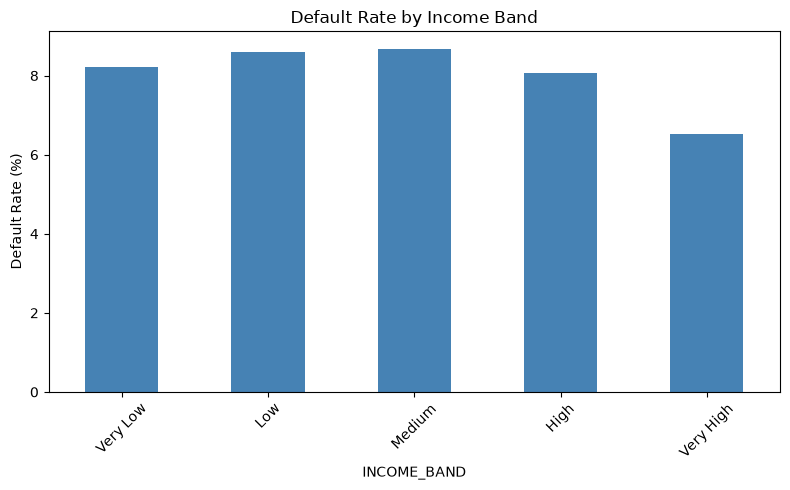

In [3]:
# Create income bands and calculate default rates
app['INCOME_BAND'] = pd.qcut(app['AMT_INCOME_TOTAL_CAPPED'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

income_default = app.groupby('INCOME_BAND', observed=True)['TARGET'].mean() * 100

plt.figure(figsize=(8, 5))
income_default.plot(kind='bar', color='steelblue')
plt.ylabel('Default Rate (%)')
plt.title('Default Rate by Income Band')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/figures/default_by_income.png', dpi=150)
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_25128\3382100626.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  app['AGE_BAND'] = pd.cut(app['AGE_YEARS'], bins=[20, 30, 40, 50, 60, 70], labels=['20-30', '30-40', '40-50', '50-60', '60-70'])


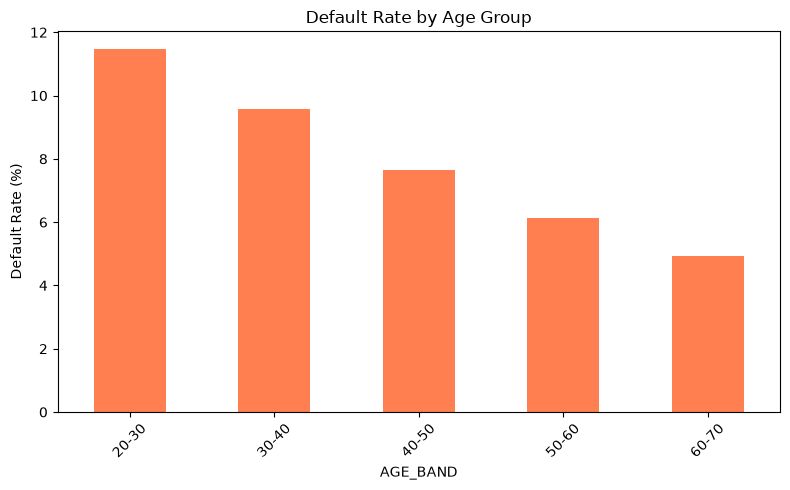

In [4]:
#Default rate by age group
app['AGE_BAND'] = pd.cut(app['AGE_YEARS'], bins=[20, 30, 40, 50, 60, 70], labels=['20-30', '30-40', '40-50', '50-60', '60-70'])

age_default = app.groupby('AGE_BAND', observed=True)['TARGET'].mean() * 100

plt.figure(figsize=(8, 5))
age_default.plot(kind='bar', color='coral')
plt.ylabel('Default Rate (%)')
plt.title('Default Rate by Age Group')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/figures/default_by_age.png', dpi=150)
plt.show()

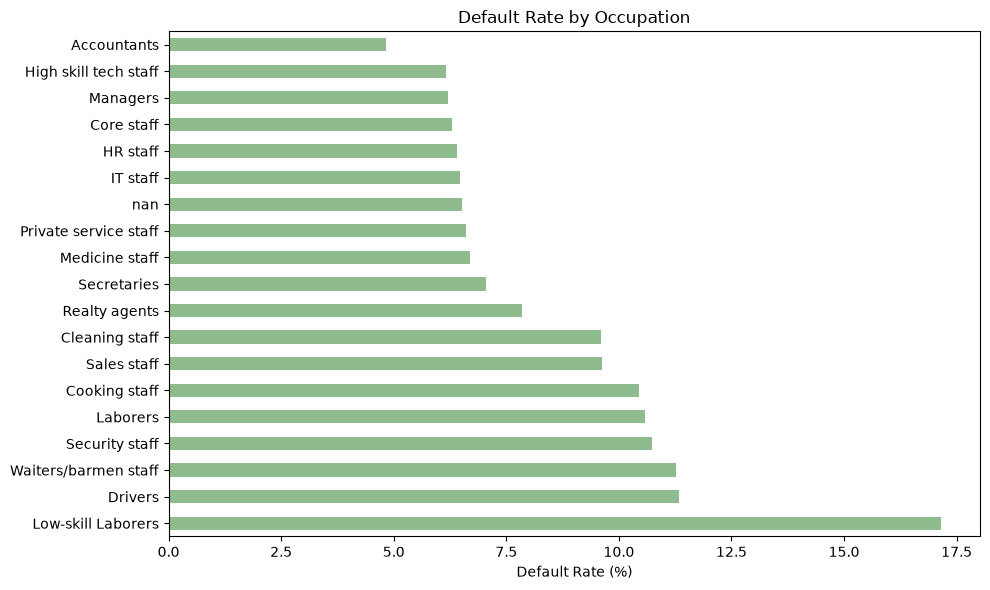

In [5]:
#Default rate by occupation type(top 10 by volume)
occ_cols = [c for c in app.columns if c.startswith('OCCUPATION_TYPE_')]
# Since these are one-hot encoded, reconstruct the default rate per occupation
occ_default = {}
for col in occ_cols:
    subset = app[app[col] == 1]
    if len(subset) > 500:  # skip tiny categories
        occ_default[col.replace('OCCUPATION_TYPE_', '')] = subset['TARGET'].mean() * 100

occ_default_series = pd.Series(occ_default).sort_values(ascending=False)

plt.figure(figsize=(10, 6))
occ_default_series.plot(kind='barh', color='darkseagreen')
plt.xlabel('Default Rate (%)')
plt.title('Default Rate by Occupation')
plt.tight_layout()
plt.savefig('../outputs/figures/default_by_occupation.png', dpi=150)
plt.show()

In [6]:
# Check actual income ranges per band
app.groupby('INCOME_BAND', observed=True)['AMT_INCOME_TOTAL_CAPPED'].agg(['min', 'max', 'mean', 'count'])

# Check if medium-income applicants are taking proportionally bigger loans
app.groupby('INCOME_BAND', observed=True)['DEBT_TO_INCOME_RATIO'].mean()

INCOME_BAND
Very Low     5.071650
Low          4.191541
Medium       3.878313
High         3.516384
Very High    2.804835
Name: DEBT_TO_INCOME_RATIO, dtype: float64

In [7]:
# Income ranges per band (the piece we're missing)
print(app.groupby('INCOME_BAND', observed=True)['AMT_INCOME_TOTAL_CAPPED'].agg(['min', 'max', 'mean', 'count']))

# Annuity-to-income ratio by band (a more precise affordability measure than raw DTI)
print(app.groupby('INCOME_BAND', observed=True)['ANNUITY_TO_INCOME_RATIO'].mean())

# Income type composition by band (checking for pensioner/unemployed skew)
print(pd.crosstab(app['INCOME_BAND'], app['NAME_INCOME_TYPE_Pensioner'], normalize='index') * 100)

                  min       max           mean  count
INCOME_BAND                                          
Very Low      25650.0   99000.0   78064.972119  63671
Low           99031.5  135000.0  123021.450037  85755
Medium       135256.5  162000.0  155407.366249  35452
High         162279.0  225000.0  198635.614872  75512
Very High    225112.5  630000.0  326134.458248  47117
INCOME_BAND
Very Low     0.239870
Low          0.192516
Medium       0.174599
High         0.156947
Very High    0.123984
Name: ANNUITY_TO_INCOME_RATIO, dtype: float64
NAME_INCOME_TYPE_Pensioner      False      True 
INCOME_BAND                                     
Very Low                    68.575961  31.424039
Low                         81.644219  18.355781
Medium                      83.969875  16.030125
High                        87.513243  12.486757
Very High                   90.447185   9.552815


C:\Users\User\AppData\Local\Temp\ipykernel_25128\2603557964.py:2: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  app['CREDIT_BAND'] = pd.qcut(app['AMT_CREDIT'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])


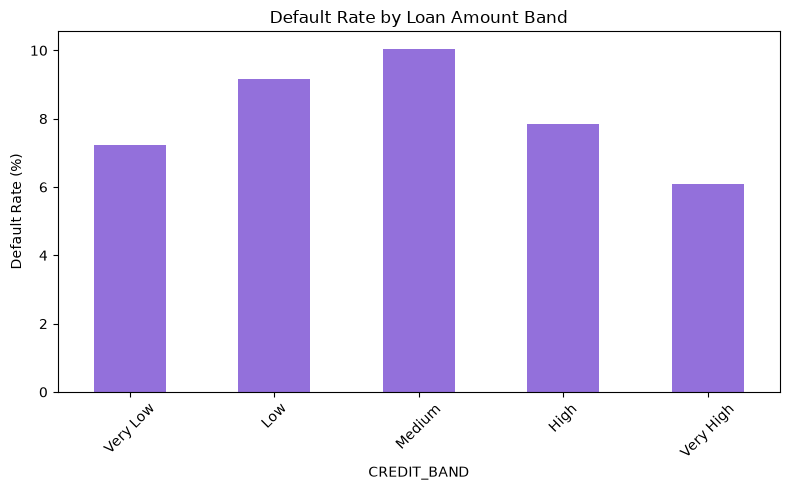

In [8]:
#Loan amount vs default risk
app['CREDIT_BAND'] = pd.qcut(app['AMT_CREDIT'], q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])

credit_default = app.groupby('CREDIT_BAND', observed=True)['TARGET'].mean() * 100

plt.figure(figsize=(8, 5))
credit_default.plot(kind='bar', color='mediumpurple')
plt.ylabel('Default Rate (%)')
plt.title('Default Rate by Loan Amount Band')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/figures/default_by_loan_amount.png', dpi=150)
plt.show()

C:\Users\User\AppData\Local\Temp\ipykernel_25128\772871205.py:3: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  app['IMPLIED_CREDIT_COST_RATIO'] = (app['AMT_CREDIT'] - app['AMT_GOODS_PRICE']) / app['AMT_GOODS_PRICE']
C:\Users\User\AppData\Local\Temp\ipykernel_25128\772871205.py:11: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  app.loc[cost_band.index, 'CREDIT_COST_BAND'] = cost_band


count    307229.000000
mean          0.122994
std           0.124036
min          -0.850000
25%           0.000000
50%           0.118800
75%           0.198000
max           5.000000
Name: IMPLIED_CREDIT_COST_RATIO, dtype: float64


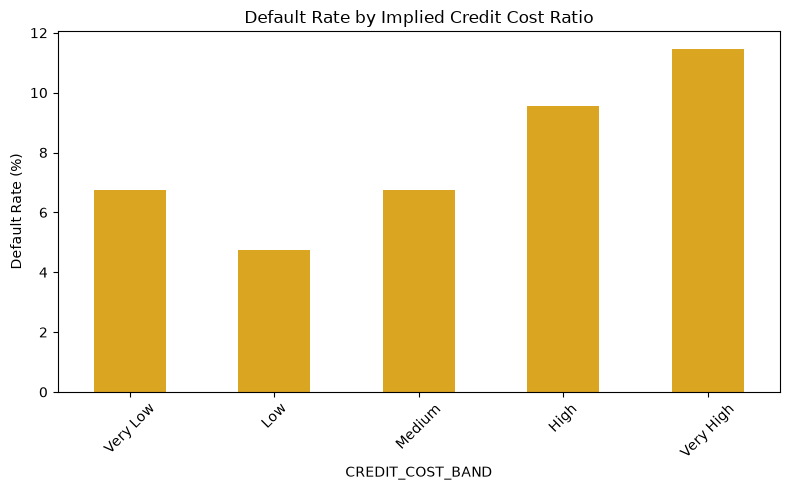

In [9]:
#implied cost of credit(substitute for interest rate)
# How much more than the goods price is the applicant paying back overall?
app['IMPLIED_CREDIT_COST_RATIO'] = (app['AMT_CREDIT'] - app['AMT_GOODS_PRICE']) / app['AMT_GOODS_PRICE']

# Some goods price values may be 0 or missing — guard against inf/extreme values
app['IMPLIED_CREDIT_COST_RATIO'] = app['IMPLIED_CREDIT_COST_RATIO'].replace([np.inf, -np.inf], np.nan)

print(app['IMPLIED_CREDIT_COST_RATIO'].describe())

cost_band = pd.qcut(app['IMPLIED_CREDIT_COST_RATIO'].dropna(), q=5, labels=['Very Low', 'Low', 'Medium', 'High', 'Very High'])
app.loc[cost_band.index, 'CREDIT_COST_BAND'] = cost_band

cost_default = app.groupby('CREDIT_COST_BAND', observed=True)['TARGET'].mean() * 100

plt.figure(figsize=(8, 5))
cost_default.plot(kind='bar', color='goldenrod')
plt.ylabel('Default Rate (%)')
plt.title('Default Rate by Implied Credit Cost Ratio')
plt.xticks(rotation=45)
plt.tight_layout()
plt.savefig('../outputs/figures/default_by_credit_cost.png', dpi=150)
plt.show()

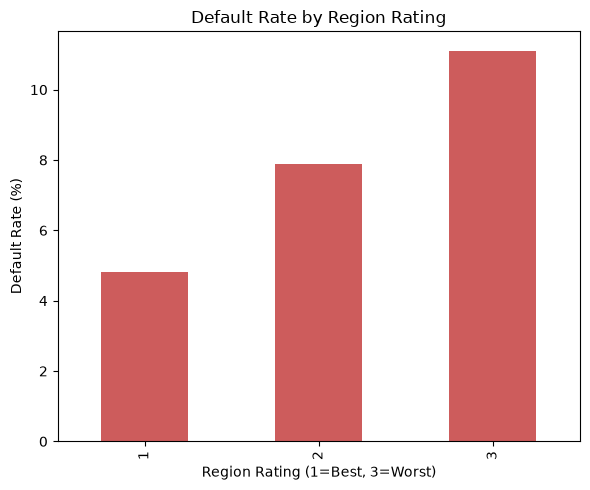

In [10]:
#Geographic analysis
region_default = app.groupby('REGION_RATING_CLIENT')['TARGET'].mean() * 100

plt.figure(figsize=(6, 5))
region_default.plot(kind='bar', color='indianred')
plt.ylabel('Default Rate (%)')
plt.xlabel('Region Rating (1=Best, 3=Worst)')
plt.title('Default Rate by Region Rating')
plt.tight_layout()
plt.savefig('../outputs/figures/default_by_region.png', dpi=150)
plt.show()

In [11]:
# Is the loan-amount hump just the income pattern in disguise?
print(app.groupby('CREDIT_BAND', observed=True)['NAME_INCOME_TYPE_Pensioner'].mean() * 100)
print(app.groupby('CREDIT_BAND', observed=True)['ANNUITY_TO_INCOME_RATIO'].mean())

CREDIT_BAND
Very Low     23.420870
Low          17.824253
Medium       16.979415
High         17.430963
Very High    13.902091
Name: NAME_INCOME_TYPE_Pensioner, dtype: float64
CREDIT_BAND
Very Low     0.124189
Low          0.152985
Medium       0.190755
High         0.208334
Very High    0.231446
Name: ANNUITY_TO_INCOME_RATIO, dtype: float64


In [12]:
dashboard_cols = [
    'SK_ID_CURR', 'TARGET', 'AMT_INCOME_TOTAL_CAPPED', 'AMT_CREDIT', 'AMT_ANNUITY',
    'AGE_YEARS', 'CODE_GENDER_M', 'INCOME_BAND', 'AGE_BAND', 'CREDIT_BAND',
    'CREDIT_COST_BAND', 'IMPLIED_CREDIT_COST_RATIO', 'REGION_RATING_CLIENT',
    'DEBT_TO_INCOME_RATIO', 'ANNUITY_TO_INCOME_RATIO', 'NAME_INCOME_TYPE_Pensioner',
    'DAYS_EMPLOYED_ANOMALY', 'NO_BUREAU_HISTORY', 'BUREAU_COUNT',
    'BUREAU_OVERDUE_COUNT', 'PREV_APP_COUNT', 'PREV_APPROVAL_RATE',
    'INSTALLMENT_LATE_RATIO', 'EXT_SOURCE_1', 'EXT_SOURCE_2', 'EXT_SOURCE_3'
]

# Add back occupation columns (currently one-hot, we'll reconstruct a readable label)
occ_cols = [c for c in app.columns if c.startswith('OCCUPATION_TYPE_')]
app['OCCUPATION_TYPE'] = app[occ_cols].idxmax(axis=1).str.replace('OCCUPATION_TYPE_', '')

dashboard_df = app[dashboard_cols + ['OCCUPATION_TYPE']].copy()
dashboard_df.to_csv('../dashboards/powerbi/credit_risk_dashboard_data.csv', index=False)
print("Saved:", dashboard_df.shape)

C:\Users\User\AppData\Local\Temp\ipykernel_25128\1679587111.py:13: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  app['OCCUPATION_TYPE'] = app[occ_cols].idxmax(axis=1).str.replace('OCCUPATION_TYPE_', '')


Saved: (307507, 27)
